# importing

In [1]:
import pandas as pd
import numpy as np
import warnings
warnings.filterwarnings("ignore", category=UserWarning)

from sklearn.model_selection import train_test_split, StratifiedKFold, cross_val_score
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import classification_report, roc_auc_score, confusion_matrix, roc_curve
from sklearn.preprocessing import LabelEncoder, StandardScaler
from sklearn.feature_selection import f_classif, chi2, SelectKBest
from imblearn.over_sampling import SMOTE
from imblearn.under_sampling import RandomUnderSampler
from imblearn.combine import SMOTEENN
import matplotlib.pyplot as plt
import seaborn as sns

# Starting Insurance Claims Prediction Pipeline


## Step 1: Load Data


In [2]:
data = pd.read_csv('Insurance_claims_data.csv')
print(f"Data shape: {data.shape}")
print(f"Columns: {data.columns.tolist()}")
class_counts = data['claim_status'].value_counts()
print()
print(class_counts)
print(f"Imbalance ratio: {class_counts[1]/class_counts[0]:.4f}")
print(f"Minority class percentage: {class_counts[1]/len(data)*100:.2f}%")

Data shape: (58592, 41)
Columns: ['policy_id', 'subscription_length', 'vehicle_age', 'customer_age', 'region_code', 'region_density', 'segment', 'model', 'fuel_type', 'max_torque', 'max_power', 'engine_type', 'airbags', 'is_esc', 'is_adjustable_steering', 'is_tpms', 'is_parking_sensors', 'is_parking_camera', 'rear_brakes_type', 'displacement', 'cylinder', 'transmission_type', 'steering_type', 'turning_radius', 'length', 'width', 'gross_weight', 'is_front_fog_lights', 'is_rear_window_wiper', 'is_rear_window_washer', 'is_rear_window_defogger', 'is_brake_assist', 'is_power_door_locks', 'is_central_locking', 'is_power_steering', 'is_driver_seat_height_adjustable', 'is_day_night_rear_view_mirror', 'is_ecw', 'is_speed_alert', 'ncap_rating', 'claim_status']

claim_status
0    54844
1     3748
Name: count, dtype: int64
Imbalance ratio: 0.0683
Minority class percentage: 6.40%


## Step 2: Create Train/Test/OOT splits (Fixed OOT issue)

In [3]:
oot_df = data.tail(8592).copy()
remaining_data = data.iloc[:-8592].copy()

train_df, test_df = train_test_split(
    remaining_data, 
    test_size=0.2, 
    random_state=42,
    stratify=remaining_data['claim_status']
)

print(f"Train size: {len(train_df)} (Claims: {train_df['claim_status'].sum()})")
print(f"Test size: {len(test_df)} (Claims: {test_df['claim_status'].sum()})")
print(f"OOT size: {len(oot_df)} (Claims: {oot_df['claim_status'].sum()})")


Train size: 40000 (Claims: 2572)
Test size: 10000 (Claims: 643)
OOT size: 8592 (Claims: 533)


## Step 3: Prepare features and target


In [4]:
X_train = train_df.drop(['claim_status', 'policy_id'], axis=1).copy()
y_train = train_df['claim_status'].copy()

X_test = test_df.drop(['claim_status', 'policy_id'], axis=1).copy()
y_test = test_df['claim_status'].copy()

X_oot = oot_df.drop(['claim_status', 'policy_id'], axis=1).copy()
y_oot = oot_df['claim_status'].copy()

print(f"Feature shape: {X_train.shape}")

categorical_cols = X_train.select_dtypes(include=['object']).columns.tolist()
numerical_cols = X_train.select_dtypes(include=['number']).columns.tolist()

print(f"Categorical columns ({len(categorical_cols)}): {categorical_cols[:5]}...")
print(f"Numerical columns ({len(numerical_cols)}): {numerical_cols[:5]}...")


Feature shape: (40000, 39)
Categorical columns (27): ['region_code', 'segment', 'model', 'fuel_type', 'max_torque']...
Numerical columns (12): ['subscription_length', 'vehicle_age', 'customer_age', 'region_density', 'airbags']...


## Step 4: Handle categorical variables with Label Encoding


In [5]:
label_encoders = {}
for col in categorical_cols:
    le = LabelEncoder()
    X_train[col] = le.fit_transform(X_train[col].astype(str))
    X_test[col] = le.transform(X_test[col].astype(str))
    X_oot[col] = le.transform(X_oot[col].astype(str))
    label_encoders[col] = le

print(f" Encoded {len(categorical_cols)} categorical variables")


 Encoded 27 categorical variables


## Step 5: Feature Selection using Statistical Tests


In [6]:
X_num = X_train[numerical_cols]
f_scores, f_p_values = f_classif(X_num, y_train)

print("ANOVA F-test scores for numerical features:")
f_results = pd.DataFrame({
    'feature': numerical_cols,
    'f_score': f_scores,
    'p_value': f_p_values
}).sort_values('f_score', ascending=False)
print(f_results.head(10))

X_cat = X_train[categorical_cols]
chi_scores, chi_p_values = chi2(X_cat, y_train)

print("\nChi-square test scores for categorical features:")
chi_results = pd.DataFrame({
    'feature': categorical_cols,
    'chi2_score': chi_scores,
    'p_value': chi_p_values
}).sort_values('chi2_score', ascending=False)
print(chi_results.head(10))

f_threshold = 7
chi_threshold = 7

good_numerical = f_results[f_results['f_score'] > f_threshold]['feature'].tolist()
good_categorical = chi_results[chi_results['chi2_score'] > chi_threshold]['feature'].tolist()

selected_features = good_numerical + good_categorical
print(f"\nSelected {len(selected_features)} features:")
print(f"Numerical: {good_numerical}")
print(f"Categorical: {good_categorical}")

X_train_selected = X_train[selected_features].copy()
X_test_selected = X_test[selected_features].copy()
X_oot_selected = X_oot[selected_features].copy()

print(f"Selected features shape: {X_train_selected.shape}")


ANOVA F-test scores for numerical features:
                feature     f_score       p_value
0   subscription_length  244.076761  7.382348e-55
1           vehicle_age   35.057107  3.227834e-09
2          customer_age   18.439699  1.757790e-05
3        region_density    9.661663  1.882852e-03
6              cylinder    6.898497  8.630111e-03
10         gross_weight    2.975485  8.454250e-02
5          displacement    2.903643  8.838737e-02
9                 width    2.887280  8.928933e-02
8                length    2.276534  1.313530e-01
4               airbags    1.285092  2.569613e-01

Chi-square test scores for categorical features:
                             feature  chi2_score   p_value
4                         max_torque    8.070051  0.004500
0                        region_code    6.882772  0.008703
1                            segment    5.496141  0.019058
8             is_adjustable_steering    2.188771  0.139020
19                   is_brake_assist    1.665285  0.196891
15

## Step 6: Handle Class Imbalance


In [7]:
print("Original class distribution:")
print(f"Class 0: {(y_train == 0).sum()}")
print(f"Class 1: {(y_train == 1).sum()}")

smote = SMOTE(random_state=42, k_neighbors=3)
X_train_balanced, y_train_balanced = smote.fit_resample(X_train_selected, y_train)

print("After SMOTE balancing:")
print(f"Class 0: {(y_train_balanced == 0).sum()}")
print(f"Class 1: {(y_train_balanced == 1).sum()}")


Original class distribution:
Class 0: 37428
Class 1: 2572
After SMOTE balancing:
Class 0: 37428
Class 1: 37428


## Step 7: Scale numerical features


In [8]:
selected_numerical = [col for col in selected_features if col in numerical_cols]
selected_categorical = [col for col in selected_features if col in categorical_cols]

scaler = StandardScaler()
if selected_numerical:
    X_train_balanced[selected_numerical] = scaler.fit_transform(X_train_balanced[selected_numerical])
    X_test_selected[selected_numerical] = scaler.transform(X_test_selected[selected_numerical])
    X_oot_selected[selected_numerical] = scaler.transform(X_oot_selected[selected_numerical])
    print(f"Scaled {len(selected_numerical)} numerical features")


Scaled 4 numerical features


## Step 8: Train Logistic Regression Model


In [9]:
log_reg = LogisticRegression(
    solver='liblinear',
    random_state=42,
    max_iter=1000,
    class_weight=None 
)

cv_scores = cross_val_score(
    log_reg, X_train_balanced, y_train_balanced,
    cv=StratifiedKFold(n_splits=5, shuffle=True, random_state=42),
    scoring='roc_auc'
)

print(f"Cross-validation AUC scores: {cv_scores}")
print(f"Mean CV AUC: {cv_scores.mean():.4f} ± {cv_scores.std():.4f}")

log_reg.fit(X_train_balanced, y_train_balanced)
print(" Model training completed")


Cross-validation AUC scores: [0.62248147 0.61948484 0.61835867 0.62054209 0.61377047]
Mean CV AUC: 0.6189 ± 0.0029
 Model training completed


## Step 9: Model Evaluation


In [10]:
def evaluate_model(model, X, y, dataset_name):
    print(f"\n {dataset_name} Set Evaluation ")
    
    y_pred = model.predict(X)
    y_pred_proba = model.predict_proba(X)[:, 1]
    
    auc = roc_auc_score(y, y_pred_proba)
    print(f"AUC Score: {auc:.4f}")
    
    print("\nClassification Report:")
    print(classification_report(y, y_pred))
    
    cm = confusion_matrix(y, y_pred)
    print("\nConfusion Matrix:")
    print(cm)
    
    tn, fp, fn, tp = cm.ravel()
    sensitivity = tp / (tp + fn)  
    specificity = tn / (tn + fp)  
    precision = tp / (tp + fp)
    
    print(f"\nAdditional Metrics:")
    print(f"Sensitivity (Recall): {sensitivity:.4f}")
    print(f"Specificity: {specificity:.4f}")
    print(f"Precision: {precision:.4f}")
    
    return auc, y_pred, y_pred_proba

train_auc, _, _ = evaluate_model(log_reg, X_train_balanced, y_train_balanced, "Training")
test_auc, test_pred, test_proba = evaluate_model(log_reg, X_test_selected, y_test, "Test")
oot_auc, oot_pred, oot_proba = evaluate_model(log_reg, X_oot_selected, y_oot, "OOT")



 Training Set Evaluation 
AUC Score: 0.6191

Classification Report:
              precision    recall  f1-score   support

           0       0.59      0.58      0.58     37428
           1       0.59      0.60      0.59     37428

    accuracy                           0.59     74856
   macro avg       0.59      0.59      0.59     74856
weighted avg       0.59      0.59      0.59     74856


Confusion Matrix:
[[21552 15876]
 [14997 22431]]

Additional Metrics:
Sensitivity (Recall): 0.5993
Specificity: 0.5758
Precision: 0.5856

 Test Set Evaluation 
AUC Score: 0.5899

Classification Report:
              precision    recall  f1-score   support

           0       0.95      0.58      0.72      9357
           1       0.08      0.54      0.14       643

    accuracy                           0.58     10000
   macro avg       0.51      0.56      0.43     10000
weighted avg       0.89      0.58      0.68     10000


Confusion Matrix:
[[5407 3950]
 [ 298  345]]

Additional Metrics:
Sensiti

## Step 10: Feature Importance Analysis


In [11]:
feature_importance = pd.DataFrame({
    'feature': selected_features,
    'coefficient': log_reg.coef_[0],
    'abs_coefficient': np.abs(log_reg.coef_[0])
}).sort_values('abs_coefficient', ascending=False)

print("Top 10 Most Important Features:")
print(feature_importance.head(10))


Top 10 Most Important Features:
               feature  coefficient  abs_coefficient
0  subscription_length     0.379108         0.379108
1          vehicle_age    -0.298292         0.298292
4           max_torque    -0.050921         0.050921
3       region_density    -0.044290         0.044290
2         customer_age    -0.028363         0.028363


## Step 11: Univariate Analysis (like in your original code)


In [12]:
univariate_results = {}
for feature in selected_features:
    simple_model = LogisticRegression(solver='liblinear', class_weight='balanced')
    X_single = X_train_selected[[feature]]
    simple_model.fit(X_single, y_train)
    
    y_pred_proba_simple = simple_model.predict_proba(X_single)[:, 1]
    auc_simple = roc_auc_score(y_train, y_pred_proba_simple)
    univariate_results[feature] = auc_simple

univariate_df = pd.DataFrame.from_dict(
    univariate_results, orient='index', columns=['AUC']
).sort_values('AUC', ascending=False)

print("Univariate AUC Scores:")
print(univariate_df)

Univariate AUC Scores:
                          AUC
subscription_length  0.589541
vehicle_age          0.535141
customer_age         0.523609
max_torque           0.512952
region_density       0.508498


## Step 12: Model Performance Summary


In [13]:
print(f"{'Dataset':<15} {'AUC Score':<10} {'Status'}")
print()
print(f"{'Training':<15} {train_auc:<10.4f} {' Good' if train_auc > 0.7 else ' Needs improvement'}")
print(f"{'Test':<15} {test_auc:<10.4f} {' Good' if test_auc > 0.7 else ' Needs improvement'}")
print(f"{'OOT':<15} {oot_auc:<10.4f} {' Good' if oot_auc > 0.7 else ' Needs improvement'}")
print("="*60)

train_test_diff = abs(train_auc - test_auc)
test_oot_diff = abs(test_auc - oot_auc)

print(f"\nOverfitting Analysis:")
print(f"Train-Test AUC difference: {train_test_diff:.4f} {' Good' if train_test_diff < 0.05 else ' Possible overfitting'}")
print(f"Test-OOT AUC difference: {test_oot_diff:.4f} {' Stable' if test_oot_diff < 0.05 else 'Model drift'}")


Dataset         AUC Score  Status

Training        0.6191      Needs improvement
Test            0.5899      Needs improvement
OOT             0.6260      Needs improvement

Overfitting Analysis:
Train-Test AUC difference: 0.0292  Good
Test-OOT AUC difference: 0.0362  Stable


## Step 13: Save Results


Results saved to CSV files

Insurance Claims Prediction Pipeline Completed Successfully!
Final Model AUC: Test=0.5899, OOT=0.6260


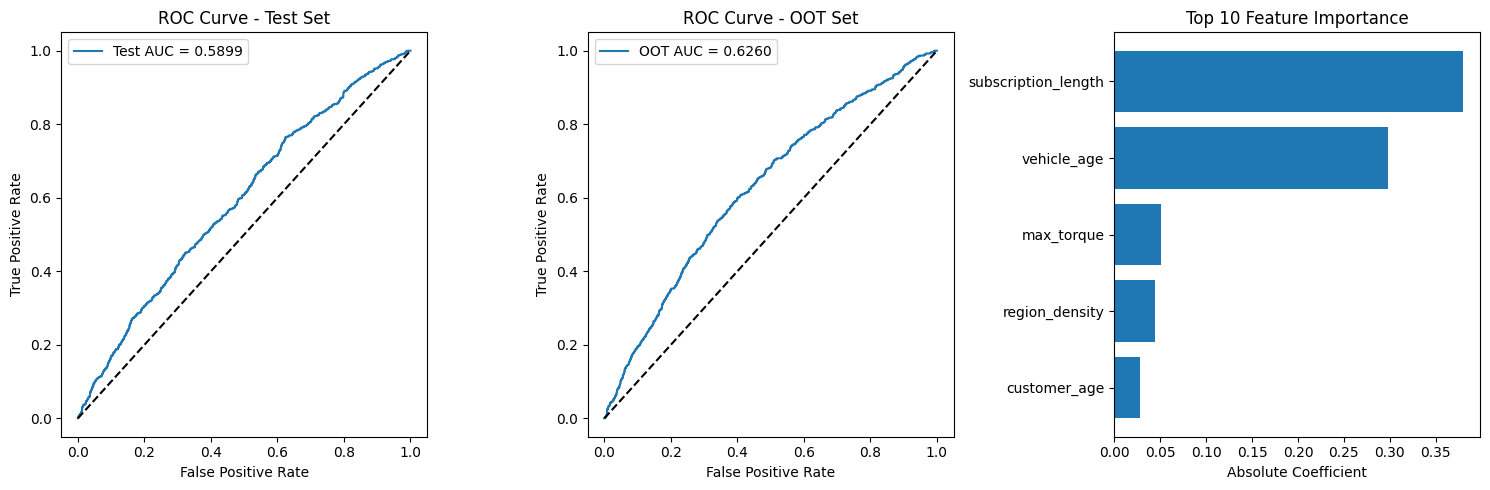

Visualization plots created and saved


In [14]:
results_df = pd.DataFrame({
    'policy_id': test_df['policy_id'].values,
    'actual': y_test.values,
    'predicted': test_pred,
    'probability': test_proba
})
results_df.to_csv('test_predictions.csv', index=False)

oot_results_df = pd.DataFrame({
    'policy_id': oot_df['policy_id'].values,
    'actual': y_oot.values,
    'predicted': oot_pred,
    'probability': oot_proba
})
oot_results_df.to_csv('oot_predictions.csv', index=False)

feature_importance.to_csv('feature_importance.csv', index=False)

univariate_df.to_csv('univariate_analysis.csv')

print("Results saved to CSV files")

print("\nInsurance Claims Prediction Pipeline Completed Successfully!")
print(f"Final Model AUC: Test={test_auc:.4f}, OOT={oot_auc:.4f}")

try:
    plt.figure(figsize=(15, 5))
    
    plt.subplot(1, 3, 1)
    fpr_test, tpr_test, _ = roc_curve(y_test, test_proba)
    plt.plot(fpr_test, tpr_test, label=f'Test AUC = {test_auc:.4f}')
    plt.plot([0, 1], [0, 1], 'k--')
    plt.xlabel('False Positive Rate')
    plt.ylabel('True Positive Rate')
    plt.title('ROC Curve - Test Set')
    plt.legend()
    
    plt.subplot(1, 3, 2)
    fpr_oot, tpr_oot, _ = roc_curve(y_oot, oot_proba)
    plt.plot(fpr_oot, tpr_oot, label=f'OOT AUC = {oot_auc:.4f}')
    plt.plot([0, 1], [0, 1], 'k--')
    plt.xlabel('False Positive Rate')
    plt.ylabel('True Positive Rate')
    plt.title('ROC Curve - OOT Set')
    plt.legend()
    
    plt.subplot(1, 3, 3)
    top_features = feature_importance.head(10)
    plt.barh(range(len(top_features)), top_features['abs_coefficient'])
    plt.yticks(range(len(top_features)), top_features['feature'])
    plt.xlabel('Absolute Coefficient')
    plt.title('Top 10 Feature Importance')
    plt.gca().invert_yaxis()
    
    plt.tight_layout()
    plt.savefig('model_evaluation_plots.png', dpi=300, bbox_inches='tight')
    plt.show()
    
    print("Visualization plots created and saved")
    
except ImportError:
    print("Matplotlib not available for plotting")